# Полносвязная нейронная сеть (FCN)

Цель работы — классификация клиентов банка по вероятности оформления срочного вклада. Был использован полный набор `bank-full.csv`, содержащий 45 211 записей до очистки. Выполняются анализ табличных данных, кодирование категориальных признаков, обучение полносвязной сети и оценка на отдельной тестовой выборке.

Источник: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing).

In [ ]:
%pip install -q numpy pandas matplotlib scipy scikit-learn torch certifi

В первой кодовой ячейке устанавливаются зависимости. Ключ `-q` сокращает служебный вывод pip. При успешной установке ошибок не появляется. PyTorch используется для вычисления градиентов и пакетного обучения.

In [2]:
import os, io, zipfile, gzip, struct, hashlib, math, json
from pathlib import Path
from urllib.request import urlopen, Request
import ssl
import certifi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score, mean_absolute_error,
    mean_squared_error, r2_score)
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display

Были подключены библиотеки для таблиц, графиков, разделения выборок и расчёта метрик. `torch.nn` содержит слои нейронных сетей, а `DataLoader` выдаёт пакеты примеров. Импорты сами по себе ничего не выводят.

In [3]:
get_ipython().run_line_magic("matplotlib", "inline")
DATA = Path(os.environ.get("ML_DATA_DIR", "data"))
DATA.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))
def seed_all():
    np.random.seed(42)
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)
seed_all()

def fetch(url, name, md5=None):
    path = DATA / name
    def check(file, sha256=None):
        if file.suffix == ".part" and file.stat().st_size == 0:
            raise ValueError("Пустой файл")
        if md5 and hashlib.md5(file.read_bytes()).hexdigest() != md5:
            raise ValueError("Неверная контрольная сумма MD5")
        if sha256 and hashlib.sha256(file.read_bytes()).hexdigest() != sha256:
            raise ValueError("Неверная контрольная сумма SHA-256 резервного архива")
        if name.endswith(".zip"):
            with zipfile.ZipFile(file) as archive:
                if archive.testzip() is not None:
                    raise ValueError("Повреждённый ZIP")
    if path.exists():
        try:
            check(path)
            return path
        except (OSError, ValueError, zipfile.BadZipFile) as exc:
            print(f"Кэш {name} повреждён: {exc}. Повторная загрузка.")
    sources = [(url, None)]
    if name == "bank_marketing.zip":
        # Резервная копия оригинального UCI bank.zip, содержащего bank-full.csv.
        sources.append(("https://raw.githubusercontent.com/raederhans/ca6003-bank-marketing/main/data/source/bank.zip",
                        "99d7e8eb12401ed278b793984423915411ea8df099e1795f9fefe254f513fe5e"))
    tmp = path.with_suffix(path.suffix + ".part")
    errors = []
    for address, sha256 in sources:
        for label, context in [("системные CA", ssl.create_default_context()),
                               ("certifi", ssl.create_default_context(cafile=certifi.where()))]:
            try:
                with urlopen(Request(address, headers={"User-Agent": "Python ML coursework"}),
                             timeout=120, context=context) as response, tmp.open("wb") as out:
                    while chunk := response.read(1024*1024):
                        out.write(chunk)
                check(tmp, sha256)
                tmp.replace(path)
                print(f"Загружен {name}: {address} ({label})")
                return path
            except (OSError, ValueError, zipfile.BadZipFile) as exc:
                tmp.unlink(missing_ok=True)
                errors.append(f"{address} ({label}): {exc}")
                print(errors[-1])
    raise RuntimeError(f"Не удалось безопасно скачать {name}. Проверьте дату Windows, сертификаты и соединение. "
                       f"Можно скачать оригинальный файл вручную и сохранить как {path}.\n" + "\n".join(errors))

def loader(x, y, batch=256, shuffle=False, regression=False):
    a = torch.as_tensor(np.ascontiguousarray(x), dtype=torch.float32)
    b = torch.as_tensor(np.ascontiguousarray(y), dtype=torch.float32 if regression else torch.long)
    return DataLoader(TensorDataset(a,b), batch_size=batch, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(42), num_workers=0)

def evaluate(model, batches, loss_fn, regression=False):
    model.eval(); total=0.; count=0; outputs=[]; targets=[]
    with torch.no_grad():
        for x,y in batches:
            yhat=model(x.to(DEVICE)); y=y.to(DEVICE)
            total += loss_fn(yhat,y).item()*len(y); count += len(y)
            outputs.append(yhat.cpu().numpy()); targets.append(y.cpu().numpy())
    return total/count, np.concatenate(outputs), np.concatenate(targets)

def fit_net(model, train, val, loss_fn, epochs, lr, regression=False):
    model.to(DEVICE); optim=torch.optim.Adam(model.parameters(),lr=lr)
    history=[]; best=float("inf"); best_state=None
    for epoch in range(1,epochs+1):
        model.train(); sum_loss=0.; count=0
        for x,y in train:
            x,y=x.to(DEVICE),y.to(DEVICE)
            optim.zero_grad(); pred=model(x); loss=loss_fn(pred,y)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),5.0); optim.step()
            sum_loss+=loss.item()*len(y); count+=len(y)
        vloss, vp, vy=evaluate(model,val,loss_fn,regression)
        score=float(np.sqrt(np.mean((vp-vy)**2))) if regression else float(np.mean(vp.argmax(1)==vy))
        history.append((epoch,sum_loss/count,vloss,score))
        if vloss<best:
            best=vloss; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        print(f"Epoch {epoch:02d}: train loss={sum_loss/count:.4f}; val loss={vloss:.4f}; val score={score:.4f}")
    model.load_state_dict(best_state)
    return pd.DataFrame(history,columns=["epoch","train_loss","val_loss","val_score"])

def chart(title,xlabel,ylabel):
    plt.title(title); plt.xlabel(xlabel); plt.ylabel(ylabel); plt.tight_layout(); plt.show(); plt.close()

def heat(a,labels,title,xlabel,ylabel,fmt):
    a=np.asarray(a); plt.figure(figsize=(9,7)); plt.imshow(a,cmap="Blues",aspect="auto"); plt.colorbar()
    plt.xticks(range(len(labels)),labels,rotation=45,ha="right"); plt.yticks(range(len(labels)),labels)
    for i in range(a.shape[0]):
        for j in range(a.shape[1]):
            plt.text(j,i,format(a[i,j],fmt),ha="center",va="center",fontsize=7,
                     color="white" if a[i,j]>a.max()*0.55 else "black")
    chart(title,xlabel,ylabel)

def size_table(train,val,test):
    assert train>=20000, "Training set must contain at least 20,000 examples"
    return {"Train":int(train),"Validation":int(val),"Test":int(test)}

def class_metrics(y,p):
    return {"Accuracy":accuracy_score(y,p),"Macro Precision":precision_score(y,p,average="macro",zero_division=0),
            "Macro Recall":recall_score(y,p,average="macro",zero_division=0),"Macro F1":f1_score(y,p,average="macro",zero_division=0)}
print("Устройство:",DEVICE)

Устройство: cpu


`fetch` сохраняет исходный файл локально, при наличии контрольной суммы проверяет целостность. Для HTTPS используются системные сертификаты или набор `certifi`; проверка сертификатов остаётся включённой. Если основной источник Bank Marketing недоступен, используется копия исходного архива `bank.zip` с проверкой SHA-256. `loader` формирует батчи без копирования примеров между выборками. В `fit_net` последовательно выполняются прямой проход, вычисление функции потерь, `backward()` и обновление весов Adam. Валидация выполняется без градиентов; сохраняется состояние с минимальной ошибкой Validation. Test здесь не используется. `size_table` проверяет наличие не менее 20 000 обучающих примеров. В выводе ячейки указывается выбранное устройство CPU или CUDA.

In [4]:
seed_all()
path=fetch("https://archive.ics.uci.edu/static/public/222/bank+marketing.zip","bank_marketing.zip")
with zipfile.ZipFile(path) as z:
    names=z.namelist()
    direct=next((x for x in names if x.endswith("bank-full.csv")),None)
    if direct: df=pd.read_csv(z.open(direct),sep=";")
    else:
        nested=next(x for x in names if x.split("/")[-1]=="bank.zip")
        with zipfile.ZipFile(io.BytesIO(z.read(nested))) as b:
            df=pd.read_csv(b.open(next(x for x in b.namelist() if x.endswith("bank-full.csv"))),sep=";")
assert df.shape == (45211, 17), f"Ожидалось 45211 строк и 17 столбцов: {df.shape}"
print("Исходный размер:",df.shape)
display(df.head()); df.info()

https://archive.ics.uci.edu/static/public/222/bank+marketing.zip (системные CA): <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: certificate has expired (_ssl.c:1032)>


Загружен bank_marketing.zip: https://archive.ics.uci.edu/static/public/222/bank+marketing.zip (certifi)
Исходный размер: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


Архив UCI содержит CSV с разделителем `;`, иногда во вложенном ZIP. `df.shape` показывает число записей и столбцов, `head()` — первые пять клиентов, а `info()` — типы и число непустых значений. Целевой столбец `y` содержит ответы yes/no. После чтения проверяется исходный размер: 45 211 строк и 17 столбцов.

In [5]:
display(df.isna().sum().to_frame("Пропуски")); print("Дубликаты:",df.duplicated().sum())
display(df.describe(include="all").T)
print("Неизвестные категории:"); display(df.eq("unknown").sum().sort_values(ascending=False))
num=df.select_dtypes(include="number").columns
q1,q3=df[num].quantile(.25),df[num].quantile(.75); iqr=q3-q1
display(((df[num]<q1-1.5*iqr)|(df[num]>q3+1.5*iqr)).sum().to_frame("IQR"))
# duration известен только после звонка
features=df.drop(columns=["duration","y"])
valid=df.y.isin(["yes","no"]) & df.age.between(18,120) & df.day.between(1,31) & (df.campaign>=1) & (df.previous>=0) & (df.pdays>=-1)
print("Некорректных строк:",int((~valid).sum()))
clean=df.loc[valid].drop(columns="duration").dropna().drop_duplicates()
# одинаковый набор признаков с разными метками исключается из обеих групп
keys=clean.drop(columns="y").columns.tolist()
conflicts=clean.duplicated(subset=keys,keep=False)
print("Неоднозначные повторяющиеся признаки:",int(conflicts.sum()))
clean=clean.loc[~conflicts].reset_index(drop=True)
print("После очистки:",clean.shape)

,Пропуски
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


Дубликаты: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


Неизвестные категории:


poutcome     36959
contact      13020
education     1857
job            288
age              0
default          0
balance          0
housing          0
marital          0
loan             0
day              0
duration         0
month            0
campaign         0
pdays            0
previous         0
y                0
dtype: int64

,IQR
age,487
balance,4729
day,0
duration,3235
campaign,3064
pdays,8257
previous,8257


Некорректных строк: 0


Неоднозначные повторяющиеся признаки: 0
После очистки: (45195, 16)


`isna()` считает настоящие пропуски, `unknown` — отдельная категория, которую было решено сохранить. `describe()` показывает count, mean, std, квартили и диапазоны; IQR отмечает необычные значения, не обязательно ошибки. Были удалены невозможные записи, пропуски и повторы после исключения `duration` (длительность разговора неизвестна до звонка). `pdays=-1` означает отсутствие предыдущего контакта, а не ошибку. Строки с одинаковыми входами и противоположными метками исключены, чтобы не переносить их между выборками.

In [6]:
X=clean.drop(columns="y"); y=clean.y.eq("yes").astype(int).to_numpy()
i_train,i_temp=train_test_split(np.arange(len(y)),test_size=.30,stratify=y,random_state=42)
i_val,i_test=train_test_split(i_temp,test_size=.50,stratify=y[i_temp],random_state=42)
nums=X.select_dtypes(include="number").columns.tolist(); cats=X.select_dtypes(exclude="number").columns.tolist()
prep=ColumnTransformer([("num",StandardScaler(),nums),("cat",OneHotEncoder(handle_unknown="ignore",sparse_output=False),cats)])
a=prep.fit_transform(X.iloc[i_train]).astype(np.float32)
b=prep.transform(X.iloc[i_val]).astype(np.float32); c=prep.transform(X.iloc[i_test]).astype(np.float32)
sizes=size_table(len(a),len(b),len(c)); print(sizes); print("Признаков после кодирования:",a.shape[1])
eda=clean.iloc[i_train].copy()

{'Train': 31636, 'Validation': 6779, 'Test': 6780}
Признаков после кодирования: 50


Разбиение 70/15/15 сделано со стратификацией по меткам. `fit_transform` вычисляет параметры стандартизации и список категорий только на Train; `transform` использует их для других частей. `sizes` содержит число уникальных строк после очистки, а второй вывод — число входов после one-hot-кодирования. Все следующие графики исходных признаков построены на Train.

### Распределение классов

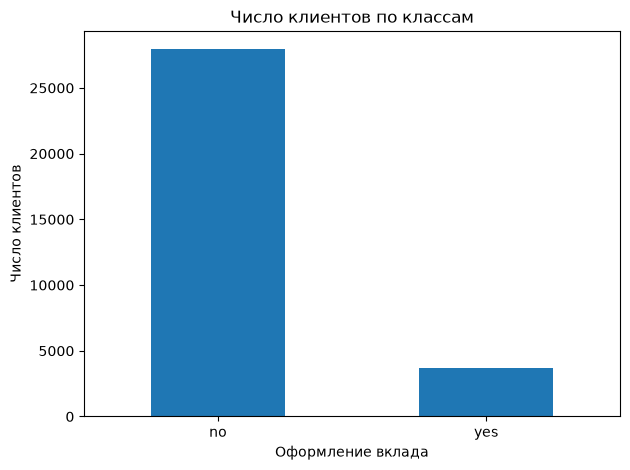

In [7]:
plt.figure(); eda.y.value_counts().reindex(["no","yes"]).plot.bar(rot=0); chart("Число клиентов по классам", "Оформление вклада", "Число клиентов")

Столбцы показывают количество клиентов с ответами no и yes. Различие высот отражает дисбаланс; поэтому одной Accuracy недостаточно, используется Macro F1 и полнота положительного класса.

### Гистограмма возраста

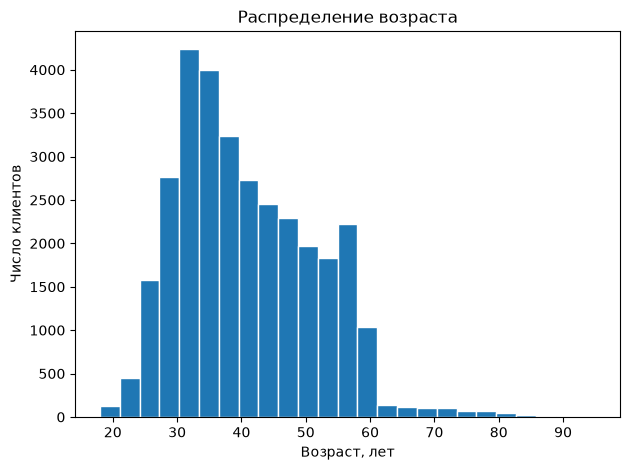

In [8]:
plt.figure(); plt.hist(eda.age,bins=25,edgecolor="white"); chart("Распределение возраста", "Возраст, лет", "Число клиентов")

Гистограмма делит возраст на 25 интервалов. Высота столбца соответствует числу клиентов; по форме можно определить наиболее распространённый возраст и крайние группы.

### Диаграмма размаха баланса

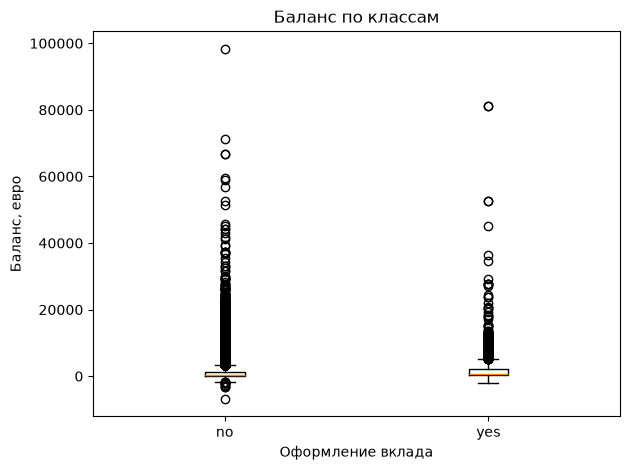

In [9]:
plt.figure(); plt.boxplot([eda.loc[eda.y==k,"balance"] for k in ["no","yes"]],tick_labels=["no","yes"],showfliers=True); chart("Баланс по классам", "Оформление вклада", "Баланс, евро")

Линия внутри коробки — медиана, границы — первый и третий квартили; усы ограничены правилом 1,5 IQR. Точки вне усов могут быть реальными крупными суммами. Сопоставляются различия распределений двух классов.

### Эмпирическая функция распределения

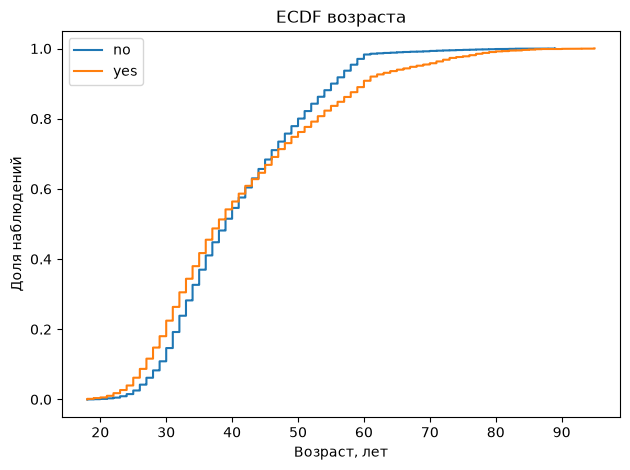

In [10]:
plt.figure();
for k in ["no","yes"]:
    v=np.sort(eda.loc[eda.y==k,"age"].to_numpy()); plt.step(v,np.arange(1,len(v)+1)/len(v),where="post",label=k)
plt.legend(); chart("ECDF возраста", "Возраст, лет", "Доля наблюдений")

ECDF показывает долю клиентов с возрастом не больше значения по X. Расхождение кривых отражает различие распределений, но не устанавливает причинную связь.

### Диаграмма рассеяния

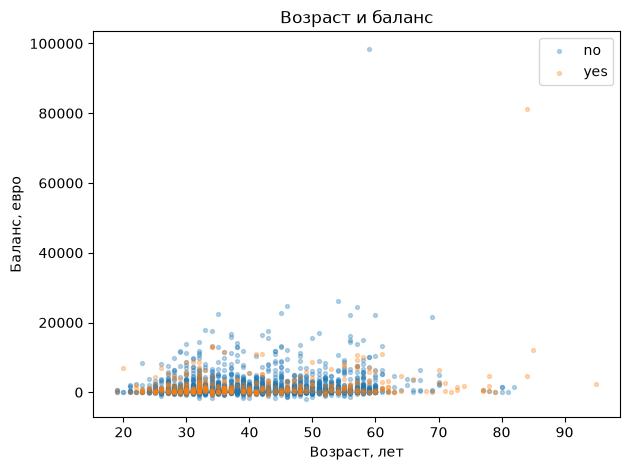

In [11]:
plt.figure(); sample=eda.sample(min(3000,len(eda)),random_state=42)
for k in ["no","yes"]:
    z=sample[sample.y==k]; plt.scatter(z.age,z.balance,s=8,alpha=.3,label=k)
plt.legend(); chart("Возраст и баланс", "Возраст, лет", "Баланс, евро")

Каждая точка — одна запись из случайной подвыборки Train для читаемости. Перекрытие цветов показывает, почему двух признаков может быть недостаточно для разделения классов. Обучение использует всю Train.

### Корреляционная матрица

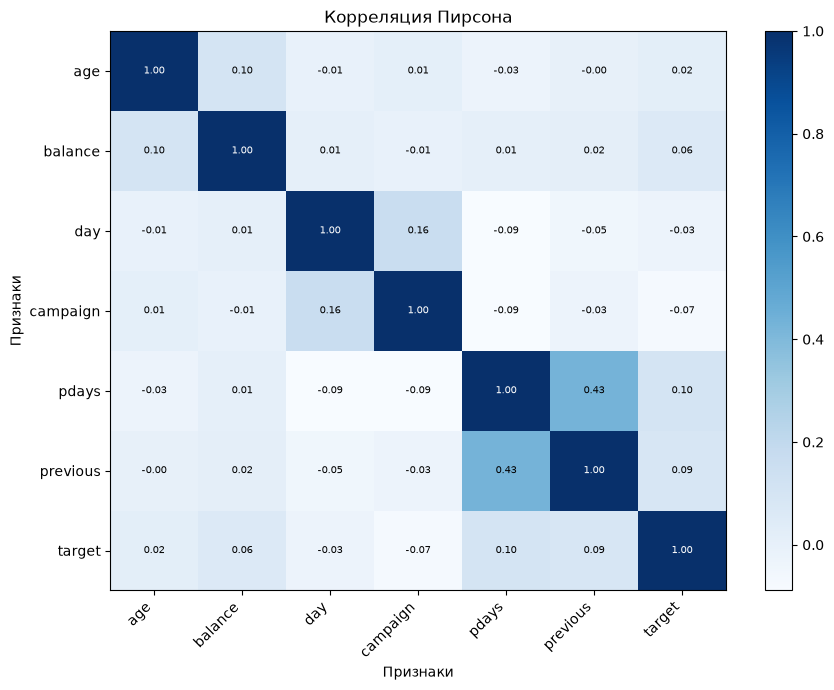

In [12]:
corr=eda[nums].assign(target=eda.y.eq("yes").astype(int)).corr(); heat(corr,corr.columns,"Корреляция Пирсона", "Признаки", "Признаки", ".2f")

Коэффициенты от −1 до 1 характеризуют линейную связь числовых признаков. Диагональ равна единице для непостоянных признаков; отрицательные значения не означают слабую связь. Корреляция не доказывает причинность.

In [13]:
train=loader(a,y[i_train],shuffle=True); val=loader(b,y[i_val]); test=loader(c,y[i_test])
model=nn.Sequential(nn.Linear(a.shape[1],64),nn.ReLU(),nn.Linear(64,32),nn.ReLU(),nn.Linear(32,2))
weights=torch.tensor(len(i_train)/(2*np.bincount(y[i_train])),dtype=torch.float32,device=DEVICE)
loss_fn=nn.CrossEntropyLoss(weight=weights)
print(model); print("Параметров:",sum(p.numel() for p in model.parameters()))
history=fit_net(model,train,val,loss_fn,epochs=20,lr=.001)
_, logits, true=evaluate(model,test,loss_fn)
prob=torch.softmax(torch.tensor(logits),dim=1).numpy()[:,1]; pred=logits.argmax(1)
m=class_metrics(true,pred); m.update({"Precision (yes)":precision_score(true,pred,zero_division=0),"Recall (yes)":recall_score(true,pred,zero_division=0),"ROC-AUC":roc_auc_score(true,prob),"PR-AUC (AP)":average_precision_score(true,prob)})
print(m); print(classification_report(true,pred,target_names=["no","yes"],zero_division=0))

Sequential(
  (0): Linear(in_features=50, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=2, bias=True)
)
Параметров: 5410


Epoch 01: train loss=0.6143; val loss=0.5700; val score=0.7383


Epoch 02: train loss=0.5626; val loss=0.5571; val score=0.7656


Epoch 03: train loss=0.5532; val loss=0.5584; val score=0.7137


Epoch 04: train loss=0.5485; val loss=0.5574; val score=0.8124


Epoch 05: train loss=0.5418; val loss=0.5530; val score=0.8330


... (11 outputs left out)

Epoch 17: train loss=0.5071; val loss=0.5556; val score=0.8112


Epoch 18: train loss=0.5052; val loss=0.5542; val score=0.7767


Epoch 19: train loss=0.5021; val loss=0.5536; val score=0.7721


Epoch 20: train loss=0.5010; val loss=0.5642; val score=0.8224
{'Accuracy': 0.7607669616519174, 'Macro Precision': 0.6135845749342682, 'Macro Recall': 0.7208680035111313, 'Macro F1': 0.623271190370353, 'Precision (yes)': 0.28095238095238095, 'Recall (yes)': 0.6687657430730478, 'ROC-AUC': 0.7878103063319029, 'PR-AUC (AP)': 0.41737437983358167}
              precision    recall  f1-score   support

          no       0.95      0.77      0.85      5986
         yes       0.28      0.67      0.40       794

    accuracy                           0.76      6780
   macro avg       0.61      0.72      0.62      6780
weighted avg       0.87      0.76      0.80      6780



Полносвязные слои преобразуют входы в 64, затем 32 скрытых нейрона; ReLU добавляет нелинейность. Два выходных логита соответствуют no/yes. Веса CrossEntropy вычисляются только по Train и компенсируют дисбаланс; softmax превращает логиты в вероятностные оценки (они не обязаны быть калиброваны). В ходе 20 эпох печатаются потери Train/Validation и Accuracy Validation; итоговая модель выбрана по Validation loss. В отчёте Test `precision` — доля правильных прогнозов класса, `recall` — доля найденных объектов класса, `f1-score` — гармоническое среднее, `support` — число объектов.

### Кривые функции потерь

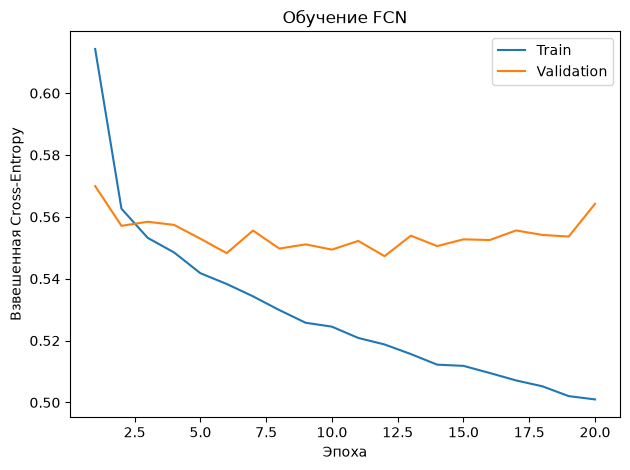

In [14]:
plt.figure(); plt.plot(history.epoch,history.train_loss,label="Train"); plt.plot(history.epoch,history.val_loss,label="Validation"); plt.legend(); chart("Обучение FCN", "Эпоха", "Взвешенная Cross-Entropy")

Снижение обеих кривых указывает на уменьшение ошибки. Рост Validation при дальнейшем падении Train может свидетельствовать о переобучении; выбор весов выполнялся по минимуму Validation.

### Матрица ошибок

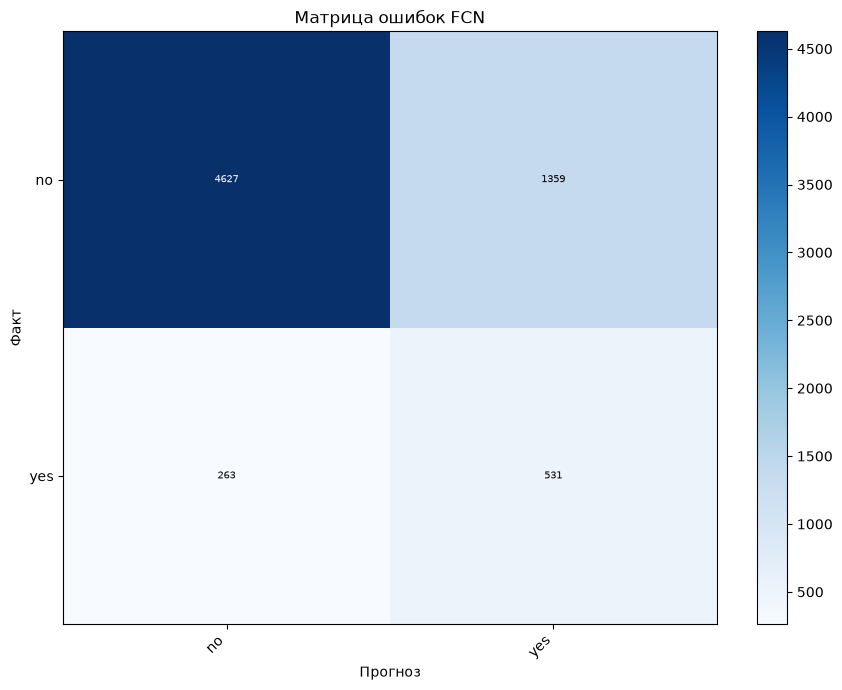

In [15]:
cm=confusion_matrix(true,pred,labels=[0,1]); heat(cm,["no","yes"],"Матрица ошибок FCN", "Прогноз", "Факт", "d")

На диагонали — верные ответы. Верхняя правая клетка — ошибочное предсказание вклада, нижняя левая — пропущенный вклад. Числа дают абсолютное количество ошибок.

### ROC-кривая

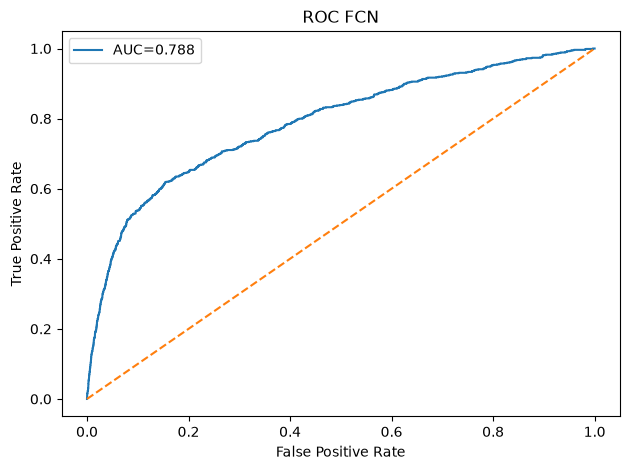

In [16]:
fpr,tpr,_=roc_curve(true,prob); plt.figure(); plt.plot(fpr,tpr,label=f"AUC={m['ROC-AUC']:.3f}"); plt.plot([0,1],[0,1],"--"); plt.legend(); chart("ROC FCN", "False Positive Rate", "True Positive Rate")

Кривая показывает компромисс между долей ложных срабатываний и долей найденных положительных объектов при разных порогах. Чем ближе линия к левому верхнему углу, тем лучше ранжирование.

### Кривая Precision–Recall

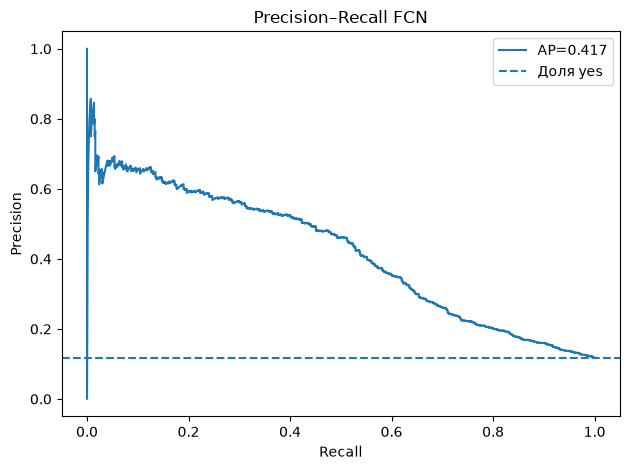

In [17]:
p,r,_=precision_recall_curve(true,prob); plt.figure(); plt.plot(r,p,label=f"AP={m['PR-AUC (AP)']:.3f}"); plt.axhline(true.mean(),ls="--",label="Доля yes"); plt.legend(); chart("Precision–Recall FCN", "Recall", "Precision")

PR-кривая особенно полезна для редкого положительного класса. Пунктир показывает долю положительных объектов, а AP характеризует качество ранжирования по precision и recall.

### Распределение оценок модели

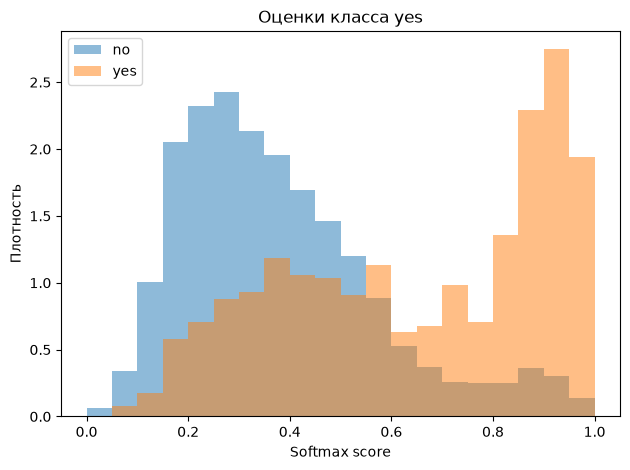

In [18]:
plt.figure();
for k in [0,1]: plt.hist(prob[true==k],bins=np.linspace(0,1,21),density=True,alpha=.5,label=["no","yes"][k])
plt.legend(); chart("Оценки класса yes", "Softmax score", "Плотность")

По оси X — оценка принадлежности к yes, по Y — нормированная плотность. Перекрытие отражает неоднозначные случаи; взвешенная функция потерь может влиять на калибровку вероятностей.

### Метрики по классам

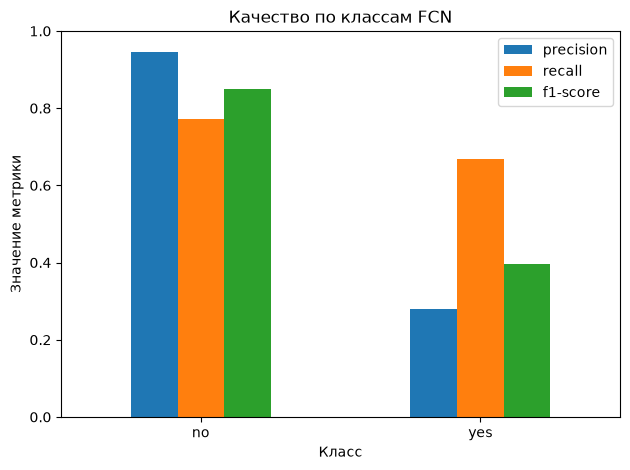

In [19]:
rep=pd.DataFrame(classification_report(true,pred,target_names=["no","yes"],output_dict=True,zero_division=0)).T.loc[["no","yes"],["precision","recall","f1-score"]]; rep.plot.bar(rot=0,ylim=(0,1)); chart("Качество по классам FCN", "Класс", "Значение метрики")

Группы столбцов сравнивают качество для каждого класса. Низкий Recall класса yes означает пропущенные вклады. Macro F1 усредняет F1 классов без учёта их численности.

In [20]:
REPORT = {"sizes": sizes, "metrics": m, "conclusion": f"После очистки для обучения использовано {sizes['Train']} клиентов. Accuracy={m['Accuracy']:.3f}, Macro F1={m['Macro F1']:.3f}, Recall yes={m['Recall (yes)']:.3f}; ROC-AUC={m['ROC-AUC']:.3f}. При дисбалансе следует учитывать полноту класса yes, а не только общую точность."}
print(REPORT["conclusion"])

После очистки для обучения использовано 31636 клиентов. Accuracy=0.761, Macro F1=0.623, Recall yes=0.669; ROC-AUC=0.788. При дисбалансе следует учитывать полноту класса yes, а не только общую точность.


В итоговой строке выводится вывод по фактическим размерам обучающей выборки и метрикам Test.